# Spin Echo T2e

In [ ]:
from pathlib import Path

import numpy as np

from qblox_lab.config.hardware import create_hardware_agent
from qblox_lab.config.sessions import CONFIG_DIR, SESSIONS
from qblox_lab.config.session_paths import save_config_snapshot, save_result_figures
from qblox_lab.experiments.cal12b_spin_echo import SpinEcho

/home/boris0403/qblox-measurement-nodes/src/qblox_lab/experiments/cal12b_spin_echo.py:14: FutureWarning: The 'qblox_scheduler.experiments' module has been renamed to 'qblox_scheduler.segments' and will be removed starting with the 1.0 release. Please update your imports to use 'qblox_scheduler.segments' instead.
  from qblox_scheduler.experiments import SetHardwareOption, SetParameter


## Run parameters

In [22]:
SESSION = SESSIONS["AS_QRC"]
HARDWARE_CONFIG = SESSION.hardware_config
DEVICE_CONFIG = SESSION.device_config
FLUX_CONFIG = SESSION.flux_config  # If None, leave the existing hardware flux unchanged
OUTPUT_DIR = SESSION.output_dir
EXPERIMENT_NAME = "spin_echo"

QUBITS = ["q3"]
DELAYS = np.arange(start=0.1, stop=50, step=0.5) * 1e-6
REPETITIONS = 1000
RESET_TYPE = "thermal"  # "thermal" or "active" (ConditionalReset)

READOUT_AMPLITUDE = None
DRIVE_OUTPUT_ATTENUATION = None
READOUT_OUTPUT_ATTENUATION = None
READOUT_INPUT_ATTENUATION = None
TIMEOUT = 300
CREATE_DUMMY_CONNECTIONS = False

PLOT_RESULTS = True

## Hardware and experiment

In [23]:
import atexit

from qcodes.instrument import Instrument

hardware_agent = create_hardware_agent(
    hardware_configuration=HARDWARE_CONFIG,
    device_configuration=DEVICE_CONFIG,
    output_dir=OUTPUT_DIR,
    create_dummy_connections=CREATE_DUMMY_CONNECTIONS,
)

experiment = SpinEcho(
    hardware_agent=hardware_agent,
    qubits=QUBITS,
    flux_config=FLUX_CONFIG,
)

atexit.register(Instrument.close_all)

<bound method Instrument.close_all of <class 'qcodes.instrument.instrument.Instrument'>>

## Measurement

In [24]:
dataset = experiment.run_measurement(
    delays=DELAYS,
    repetitions=REPETITIONS,
    reset_type=RESET_TYPE,
    readout_amplitude=READOUT_AMPLITUDE,
    drive_output_attenuation=DRIVE_OUTPUT_ATTENUATION,
    readout_output_attenuation=READOUT_OUTPUT_ATTENUATION,
    readout_input_attenuation=READOUT_INPUT_ATTENUATION,
    timeout=TIMEOUT,
)
dataset

/home/boris0403/y/envs/qblox/lib/python3.10/site-packages/qblox_scheduler/operations/gate_library.py:1181: FutureWarning: Using the `acq_channel` argument is deprecated. Use the `acq_label` argument instead.
  warn_acq_channel()
[ic_cluster_A_module6|seq0] ACQ_SCOPE_OUT_OF_RANGE_PATH_0 - Scope acquisition data for path 0 was out-of-range.
[ic_cluster_A_module6|seq0] ACQ_SCOPE_OUT_OF_RANGE_PATH_1 - Scope acquisition data for path 1 was out-of-range.
[ic_cluster_A_module6|seq0] ACQ_INTEGRATOR_OUT_OF_RANGE_PATH_0 - Acquisition integration input data for path 0 was out-of-range.
[ic_cluster_A_module6|seq0] ACQ_INTEGRATOR_OUT_OF_RANGE_PATH_1 - Acquisition integration input data for path 1 was out-of-range.
[ic_cluster_A_module6|seq8] ACQ_INTEGRATOR_OUT_OF_RANGE_PATH_0 - Acquisition integration input data for path 0 was out-of-range.
[ic_cluster_A_module6|seq8] ACQ_INTEGRATOR_OUT_OF_RANGE_PATH_1 - Acquisition integration input data for path 1 was out-of-range.
[ic_cluster_A_module6|seq9] ACQ

---
---


<xarray.Dataset> Size: 2kB
Dimensions:           (acq_index_S21_q3: 100)
Coordinates:
  * acq_index_S21_q3  (acq_index_S21_q3) int64 800B 0 1 2 3 4 ... 95 96 97 98 99
    delay_q3          (acq_index_S21_q3) float64 800B 1e-07 6e-07 ... 4.96e-05
Data variables:
    S21_q3            (acq_index_S21_q3) float64 800B 0.324 0.275 ... 0.487 0.49
Attributes:
    tuid:     20260929-235709-201-b34a3b

## Optional: Simulated data

In [5]:
# dataset = experiment.simulated_data(
#     delays=DELAYS,
#     repetitions=REPETITIONS,
#     t1=100e-6,
#     noise=0.002,
#     seed=42,
# )

## Analysis

In [25]:
results = experiment.analysis()
for qubit, result in results.items():
    if result.success:
        print(f"{qubit}: T2e = {result.t2e / 1e-6:.3f} us")
    else:
        print(f"{qubit}: T2e fit failed")

q3: T2e = 33.388 us


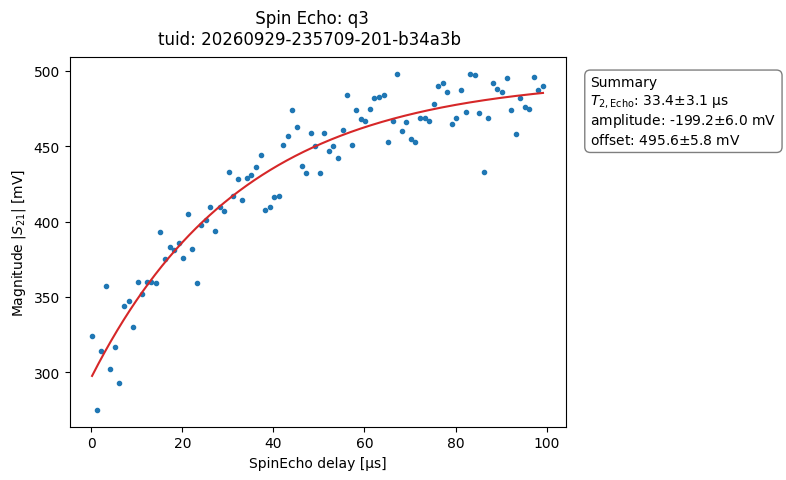

In [26]:
if PLOT_RESULTS:
    experiment.plot()

In [27]:
if PLOT_RESULTS and experiment.figures:
    save_result_figures(SESSION, dataset, EXPERIMENT_NAME, experiment.figures)
save_config_snapshot(SESSION, dataset, EXPERIMENT_NAME)


## Release hardware connection

In [ ]:
from qcodes.instrument import Instrument

Instrument.close_all()